In [1]:
from game_agent_friendly import PolicyNetwork, Agent, generate
import torch
import numpy as np
%matplotlib widget

Testing the functioning of the policy network, with a totally random policy and checking that backpropagation via autodiff is working correctly.

In [2]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


In [3]:
# Initialise policy network
policy_model = PolicyNetwork().to(device)
# Initialise agent using the policy network and the device the agent will use for training:
agent = Agent(policy_model, [], device)
# Initialise start state of the game:
state_0 = np.array([[0 , 0 , 0 , 0] , [0 , 2 , 0 , 0] , [0 , 0 , 2 , 0 ] , [0 , 0 ,0 , 0]])
# Generate an episode of experience: 
episode = generate(state_0 , agent)

Gameover?:  False
down
[[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [2 2 2 0]]
Gameover?:  False
up
[[2 2 2 0]
 [0 0 0 0]
 [0 0 0 0]
 [2 0 0 0]]
Gameover?:  False
left
[[4 2 0 0]
 [2 0 0 0]
 [0 0 0 0]
 [2 0 0 0]]
Gameover?:  False
up
[[4 2 0 0]
 [4 0 0 0]
 [0 0 0 0]
 [0 0 0 2]]
Gameover?:  False
down
[[0 0 0 0]
 [4 0 0 0]
 [0 0 0 0]
 [8 2 0 2]]
Gameover?:  False
right
[[0 0 2 0]
 [0 0 0 4]
 [0 0 0 0]
 [0 0 8 4]]
Gameover?:  False
up
[[0 0 2 8]
 [0 0 8 4]
 [0 0 0 0]
 [0 0 0 0]]
Gameover?:  False
down
[[0 2 0 0]
 [0 0 0 0]
 [0 0 2 8]
 [0 0 8 4]]
Gameover?:  False
up
[[0 2 2 8]
 [0 2 8 4]
 [0 0 0 0]
 [0 0 0 0]]
Gameover?:  False
down
[[0 2 0 0]
 [0 0 0 0]
 [0 0 2 8]
 [0 4 8 4]]
Gameover?:  False
left
[[2 0 0 0]
 [0 0 4 0]
 [2 8 0 0]
 [4 8 4 0]]
Gameover?:  False
up
[[ 4 16  8  0]
 [ 4  0  0  0]
 [ 0  0  0  0]
 [ 2  0  0  0]]
Gameover?:  False
left
[[ 4 16  8  0]
 [ 4  0  0  0]
 [ 0  0  0  0]
 [ 2  0  0  0]]
Gameover?:  False
down
[[ 0  0  0  0]
 [ 0  0  0  2]
 [ 8  0  0  0]
 [ 2 16  8  0]]
Gameover?

Text(0.5, 1.0, 'Reward')

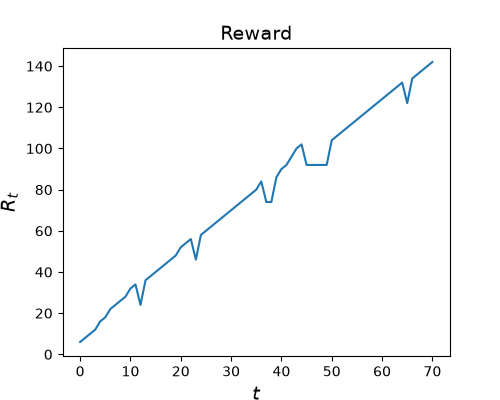

In [4]:
states , actions, rewards = episode
# Print Rewards over time: 
import matplotlib.pyplot as plt

fig , ax = plt.subplots(figsize = (5 , 4)) 
ax.plot(rewards)
ax.set_xlabel(r'$t$', fontsize = 14)
ax.set_ylabel(r'$R_{t}$' , fontsize = 14)
ax.set_title('Reward' , fontsize = 14)

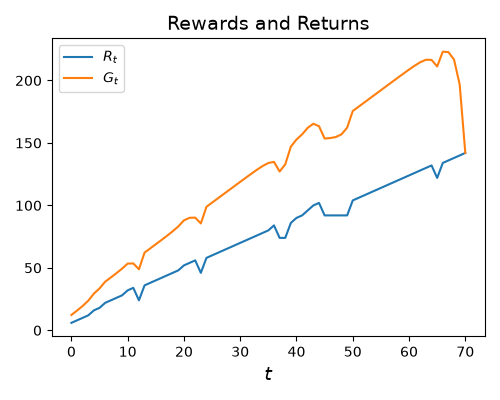

In [5]:
def G_t(t, rewards, episode_length, gamma): 
    '''
    Computes return in state at time t
    '''
    d = np.array([gamma**i for i in range(episode_length - t)])
    r = rewards[t:]
    return d@r 

G = [G_t(t , rewards , len(rewards), 0.4) for t in range(len(rewards))]

fig , ax = plt.subplots(figsize = (5 , 4)) 
ax.plot(rewards, label = r'$R_{t}$')
ax.plot(G , label = r'$G_{t}$')
ax.set_xlabel(r'$t$', fontsize = 14)
ax.set_title('Rewards and Returns' , fontsize = 14)
ax.legend() 
plt.tight_layout()

Attempting to implement reinforce gradients also: 

In [6]:
# Inspecting the policy networks weights and biases:
for name, param in PolicyNetwork().named_parameters():
    print(f"Layer: {name} | Size: {param.size()} | Values : {param[:2]} \n")

Layer: linear_relu_softmax.0.weight | Size: torch.Size([10, 16]) | Values : tensor([[-0.0105,  0.1220, -0.1424, -0.1941, -0.1551, -0.2465, -0.0402,  0.1377,
         -0.0577, -0.0247,  0.0252,  0.0054, -0.1673, -0.2293, -0.1933,  0.0245],
        [-0.0082, -0.1711,  0.0351, -0.0372,  0.1363, -0.2474, -0.0112, -0.0875,
         -0.1306, -0.0593,  0.0954, -0.0520,  0.2272,  0.0388,  0.2347, -0.1477]],
       grad_fn=<SliceBackward0>) 

Layer: linear_relu_softmax.0.bias | Size: torch.Size([10]) | Values : tensor([-0.0430, -0.0244], grad_fn=<SliceBackward0>) 

Layer: linear_relu_softmax.2.weight | Size: torch.Size([6, 10]) | Values : tensor([[-0.2385,  0.1381, -0.0844,  0.0743, -0.1753, -0.2349, -0.1217,  0.2501,
         -0.1796,  0.2437],
        [ 0.1496,  0.1004, -0.2276,  0.2203, -0.0540, -0.1044, -0.2839, -0.0766,
          0.1627,  0.1081]], grad_fn=<SliceBackward0>) 

Layer: linear_relu_softmax.2.bias | Size: torch.Size([6]) | Values : tensor([0.1735, 0.1228], grad_fn=<SliceBackwar

In [8]:
# Compiling vector of logits:
episode_logits = agent.logits
print(episode_logits)
# Inspecting the grad function of each logit obtained in the episode: 
test_grad = episode_logits[0].grad_fn
# Tracing the autograd graph back to its root:
print(test_grad.next_functions[0])
print(test_grad.next_functions[0][0].next_functions[0][0])
print(test_grad.next_functions[0][0].next_functions[0][0].next_functions[0][0])
print(test_grad.next_functions[0][0].next_functions[0][0].next_functions[0][0].next_functions[0][0])



[tensor(-1.5522, grad_fn=<SelectBackward0>), tensor(-1.3303, grad_fn=<SelectBackward0>), tensor(-1.2237, grad_fn=<SelectBackward0>), tensor(-1.3416, grad_fn=<SelectBackward0>), tensor(-1.5553, grad_fn=<SelectBackward0>), tensor(-1.5895, grad_fn=<SelectBackward0>), tensor(-1.2997, grad_fn=<SelectBackward0>), tensor(-1.3524, grad_fn=<SelectBackward0>), tensor(-1.3847, grad_fn=<SelectBackward0>), tensor(-1.2968, grad_fn=<SelectBackward0>), tensor(-1.1956, grad_fn=<SelectBackward0>), tensor(-1.4604, grad_fn=<SelectBackward0>), tensor(-1.5426, grad_fn=<SelectBackward0>), tensor(-1.2116, grad_fn=<SelectBackward0>), tensor(-1.6296, grad_fn=<SelectBackward0>), tensor(-1.4243, grad_fn=<SelectBackward0>), tensor(-1.5204, grad_fn=<SelectBackward0>), tensor(-1.0722, grad_fn=<SelectBackward0>), tensor(-1.6421, grad_fn=<SelectBackward0>), tensor(-1.5835, grad_fn=<SelectBackward0>), tensor(-1.2642, grad_fn=<SelectBackward0>), tensor(-1.4868, grad_fn=<SelectBackward0>), tensor(-1.3872, grad_fn=<Select

In [9]:
ep_logits_tensor = torch.stack(episode_logits)
print(ep_logits_tensor)
print(ep_logits_tensor.grad_fn.next_functions[0][0])
print(ep_logits_tensor.grad_fn.next_functions[0][0].next_functions[0][0])
print(ep_logits_tensor.grad_fn.next_functions[0][0].next_functions[0][0].next_functions[0][0])
print(ep_logits_tensor.grad_fn.next_functions[0][0].next_functions[0][0].next_functions[0][0].next_functions[0][0])
print(ep_logits_tensor.grad_fn.next_functions[0][0].next_functions[0][0].next_functions[0][0].next_functions[0][0].next_functions[0][0])

tensor([-1.5522, -1.3303, -1.2237, -1.3416, -1.5553, -1.5895, -1.2997, -1.3524,
        -1.3847, -1.2968, -1.1956, -1.4604, -1.5426, -1.2116, -1.6296, -1.4243,
        -1.5204, -1.0722, -1.6421, -1.5835, -1.2642, -1.4868, -1.3872, -1.5732,
        -1.3426, -1.3679, -1.5123, -1.2612, -1.5000, -1.0604, -1.0542, -1.2655,
        -1.1793, -1.3750, -0.8862, -0.9292, -1.0596, -1.0543, -0.9311, -1.9065,
        -0.8452, -1.8619, -0.7477, -2.0390, -0.7623, -0.9187, -0.9187, -0.9187,
        -0.9187, -1.0732, -1.8657, -0.9232, -0.9013, -1.0663, -0.7782, -2.5416,
        -1.6831, -1.0206, -1.6511, -1.6781, -1.4141, -1.8493, -0.9569, -1.1011,
        -1.1472, -1.1566, -2.1064, -1.4395, -2.1547, -1.0734, -2.1198],
       grad_fn=<StackBackward0>)


In [10]:
# Return tensor: 
return_tensor = torch.tensor(G, dtype = torch.float32 , device = device, requires_grad = False)
print(return_tensor)

tensor([ 12.3213,  15.8033,  19.5083,  23.7709,  29.4271,  33.5678,  38.9196,
         42.2990,  45.7476,  49.3690,  53.4225,  53.5562,  48.8905,  62.2263,
         65.5657,  68.9143,  72.2857,  75.7143,  79.2857,  83.2142,  88.0356,
         90.0889,  90.2222,  85.5555,  98.8888, 102.2221, 105.5551, 108.8878,
        112.2196, 115.5489, 118.8724, 122.1809, 125.4523, 128.6307, 131.5767,
        133.9417, 134.8542, 127.1356, 132.8390, 147.0975, 152.7437, 156.8592,
        162.1479, 165.3697, 163.4244, 153.5609, 153.9022, 154.7556, 156.8889,
        162.2222, 175.5555, 178.8889, 182.2221, 185.5553, 188.8883, 192.2207,
        195.5518, 198.8795, 202.1987, 205.4969, 208.7422, 211.8555, 214.6387,
        216.5968, 216.4920, 211.2301, 223.0752, 222.6880, 216.7200, 196.8000,
        142.0000])


In [11]:
# REINFORCE Loss: 
reinf_loss = -return_tensor.dot(ep_logits_tensor)
print(reinf_loss)
print(reinf_loss.grad_fn.next_functions[0][0].next_functions[1][0])


tensor(12114.8027, grad_fn=<NegBackward0>)


In [12]:
# Backpropagating gradient using autodiff : 
reinf_loss.backward()

In [ ]:
# Checking grads were passed through each parameter correctly: 
for name, param in policy_model.named_parameters(): 
    print('Name of parameter:', name)
    print('Gradient of parameter:', param.grad)

Name of parameter: linear_relu_softmax.0.weight
Gradient of parameter: tensor([[ 3.9965e+01,  7.7163e+01,  9.8136e+00, -1.6093e+02, -6.6210e+01,
          1.6774e+02, -4.9951e+02, -8.9890e+01, -2.6001e+01,  2.4928e+02,
         -3.5116e+02,  2.3413e+02,  2.6467e+02,  3.5416e+02, -2.8052e+02,
         -5.2670e+01],
        [ 7.6599e+01,  6.1434e+01,  2.1279e+02, -2.8456e+01,  1.0067e+02,
          1.4774e+02,  1.2787e+02,  7.2821e+01,  1.0320e+02,  2.4109e+02,
          1.2481e+03,  2.2727e+02,  4.1880e+02,  2.8787e+02,  1.0162e+02,
          1.4358e+02],
        [ 2.6097e+01,  5.3124e+01,  2.5210e+01,  5.2229e+00,  1.0760e+01,
          1.8907e+00,  1.2653e+01,  3.4169e+01,  6.1179e+00,  0.0000e+00,
          1.7424e+00,  1.7315e+01,  1.6545e+00,  9.5723e+00, -3.4343e+00,
         -9.7344e+00],
        [-7.9658e+01, -2.0298e+02, -1.0442e+02, -1.6275e+01,  1.6058e+01,
         -1.0673e+02, -4.5340e+01, -7.5590e+01,  2.3041e+01, -3.0441e+01,
         -1.5096e+01, -1.5874e+01, -2.5506e+01